In [25]:
import os

DATASET_PATH = "/kaggle/input/datasets/mohamedmustafa/real-life-violence-situations-dataset/Real Life Violence Dataset"

print("Dataset exists:", os.path.exists(DATASET_PATH))

if os.path.exists(DATASET_PATH):
    for root, dirs, files in os.walk(DATASET_PATH):
        print(root, "->", len(files), "files")
        if root.count(os.sep) - DATASET_PATH.count(os.sep) >= 2:
            dirs[:] = []

Dataset exists: True
/kaggle/input/datasets/mohamedmustafa/real-life-violence-situations-dataset/Real Life Violence Dataset -> 0 files
/kaggle/input/datasets/mohamedmustafa/real-life-violence-situations-dataset/Real Life Violence Dataset/NonViolence -> 1000 files
/kaggle/input/datasets/mohamedmustafa/real-life-violence-situations-dataset/Real Life Violence Dataset/Violence -> 1000 files


In [28]:
import os

DATASET_PATH = "/kaggle/input"

for root, dirs, files in os.walk(DATASET_PATH):
    videos = [
        f for f in files
        if f.lower().endswith((".mp4", ".avi", ".mov", ".mkv"))
    ]

    if videos:
        print("\nFolder:", root)
        print("Number of videos:", len(videos))
        print("Sample videos:", videos[:5])



Folder: /kaggle/input/datasets/mohamedmustafa/real-life-violence-situations-dataset/real life violence situations/Real Life Violence Dataset/NonViolence
Number of videos: 1000
Sample videos: ['NV_759.mp4', 'NV_564.mp4', 'NV_126.mp4', 'NV_601.mp4', 'NV_397.mp4']

Folder: /kaggle/input/datasets/mohamedmustafa/real-life-violence-situations-dataset/real life violence situations/Real Life Violence Dataset/Violence
Number of videos: 1000
Sample videos: ['V_465.mp4', 'V_313.mp4', 'V_753.mp4', 'V_963.mp4', 'V_751.mp4']

Folder: /kaggle/input/datasets/mohamedmustafa/real-life-violence-situations-dataset/Real Life Violence Dataset/NonViolence
Number of videos: 1000
Sample videos: ['NV_759.mp4', 'NV_564.mp4', 'NV_126.mp4', 'NV_601.mp4', 'NV_397.mp4']

Folder: /kaggle/input/datasets/mohamedmustafa/real-life-violence-situations-dataset/Real Life Violence Dataset/Violence
Number of videos: 1000
Sample videos: ['V_465.mp4', 'V_313.mp4', 'V_753.mp4', 'V_963.mp4', 'V_751.mp4']


In [29]:
!pip install opencv-python-headless

# **IMPORTING REQUIERD LIBRARIES**

In [30]:
import os
import shutil
import cv2
import math
import random
import numpy as np
import datetime as dt
import tensorflow
import keras
from collections import deque
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8')
%matplotlib inline

In [31]:
from sklearn.model_selection import train_test_split

from keras.layers import *
from keras.models import Sequential
from tensorflow.keras.utils import to_categorical
from keras.callbacks import EarlyStopping
from tensorflow.keras.utils import plot_model
import tensorflow as tf

# **Visualize the Data**

In [62]:
from IPython.display import HTML
from base64 import b64encode

# To Show a Video in Notebook
def Play_Video(filepath):
    html = ''
    video = open(filepath,'rb').read()
    src = 'data:video/mp4;base64,' + b64encode(video).decode()
    html += '<video width=640 muted controls autoplay loop><source src="%s" type="video/mp4"></video>' % src
    return HTML(html)

In [63]:

# Find the class directories in Kaggle's input dataset

INPUT_DIR = "/kaggle/input"

NonViolnceVideos_Dir = None
ViolnceVideos_Dir = None

for root, dirs, files in os.walk(INPUT_DIR):
    for folder in dirs:
        if folder.lower() == "nonviolence":
            NonViolnceVideos_Dir = os.path.join(root, folder)

        elif folder.lower() == "violence":
            ViolnceVideos_Dir = os.path.join(root, folder)

    if NonViolnceVideos_Dir and ViolnceVideos_Dir:
        break

if NonViolnceVideos_Dir is None or ViolnceVideos_Dir is None:
    raise FileNotFoundError(
        "Class folders not found. Check Cell 3 and the attached dataset."
    )

print("NonViolence path:", NonViolnceVideos_Dir)
print("Violence path:", ViolnceVideos_Dir)

NonViolence_files_names_list = [
    f for f in os.listdir(NonViolnceVideos_Dir)
    if f.lower().endswith((".mp4", ".avi", ".mov", ".mkv"))
]

Violence_files_names_list = [
    f for f in os.listdir(ViolnceVideos_Dir)
    if f.lower().endswith((".mp4", ".avi", ".mov", ".mkv"))
]

print("NonViolence videos:", len(NonViolence_files_names_list))
print("Violence videos:", len(Violence_files_names_list))

if not NonViolence_files_names_list or not Violence_files_names_list:
    raise ValueError("One or both classes contain no recognized video files.")

Random_NonViolence_Video = random.choice(
    NonViolence_files_names_list
)
Random_Violence_Video = random.choice(
    Violence_files_names_list
)


NonViolence path: /kaggle/input/datasets/mohamedmustafa/real-life-violence-situations-dataset/real life violence situations/Real Life Violence Dataset/NonViolence
Violence path: /kaggle/input/datasets/mohamedmustafa/real-life-violence-situations-dataset/real life violence situations/Real Life Violence Dataset/Violence
NonViolence videos: 1000
Violence videos: 1000


In [64]:
Play_Video(f"{NonViolnceVideos_Dir}/{Random_NonViolence_Video}")

In [65]:
Play_Video(f"{ViolnceVideos_Dir}/{Random_Violence_Video}")

# **Extracting Frames**

In [66]:
# Specify the height and width to which each video frame will be resized in our dataset.
IMAGE_HEIGHT , IMAGE_WIDTH = 64, 64

# Specify the number of frames of a video that will be fed to the model as one sequence.
SEQUENCE_LENGTH = 16


DATASET_DIR = os.path.dirname(NonViolnceVideos_Dir)


CLASSES_LIST = ["NonViolence","Violence"]

print("Dataset directory:", DATASET_DIR)
print("Class folders:", os.listdir(DATASET_DIR))

Dataset directory: /kaggle/input/datasets/mohamedmustafa/real-life-violence-situations-dataset/real life violence situations/Real Life Violence Dataset
Class folders: ['NonViolence', 'Violence']


In [76]:
import imageio

def frames_extraction(video_path):
  frames_list = []
  try:
    reader = imageio.get_reader(video_path, 'ffmpeg')
    num_frames= reader.count_frames()
    skip_frames_window = max(int(num_frames / SEQUENCE_LENGTH), 1)

    for frame_counter in range(0, num_frames, skip_frames_window):
      frame = reader.get_data(frame_counter)
      frame = cv2.resize(frame, (IMAGE_HEIGHT, IMAGE_WIDTH))
      frame = frame / 255.0
      frames_list.append(frame)
      if len(frames_list) == SEQUENCE_LENGTH:
        break
    reader.close()
  except Exception as e:
    print(f"Error processing {video_path}: {e}")

  return frames_list


# **Creating the Data**

In [79]:
def create_dataset():

    features = []
    labels = []
    video_files_paths = []

    # Iterating through all the classes.
    for class_index, class_name in enumerate(CLASSES_LIST):

        print(f'Extracting Data of Class: {class_name}')

        # Get the list of video files present in the specific class name directory.
        files_list = os.listdir(os.path.join(DATASET_DIR, class_name))

        # Iterate through all the files present in the files list.
        for file_name in files_list:

            # Get the complete video path.
            video_file_path = os.path.join(DATASET_DIR, class_name, file_name)

            # Extract the frames of the video file.
            frames = frames_extraction(video_file_path)

            # Check if the extracted frames are equal to the SEQUENCE_LENGTH specified.
            # So ignore the vides having frames less than the SEQUENCE_LENGTH.
            if len(frames) == SEQUENCE_LENGTH:

                # Append the data to their repective lists.
                features.append(frames)
                labels.append(class_index)
                video_files_paths.append(video_file_path)

    features = np.asarray(features)
    labels = np.array(labels)

    return features, labels, video_files_paths

In [81]:
# Create the dataset.
features, labels, video_files_paths = create_dataset()

Extracting Data of Class: NonViolence


The frame size for reading (1080, 1920) is different from the source frame size (1920, 1080).
The frame size for reading (1080, 1920) is different from the source frame size (1920, 1080).
The frame size for reading (1080, 1920) is different from the source frame size (1920, 1080).
The frame size for reading (1080, 1920) is different from the source frame size (1920, 1080).
The frame size for reading (1080, 1920) is different from the source frame size (1920, 1080).
The frame size for reading (1080, 1920) is different from the source frame size (1920, 1080).


Error processing /kaggle/input/datasets/mohamedmustafa/real-life-violence-situations-dataset/real life violence situations/Real Life Violence Dataset/NonViolence/NV_361.mp4: 105


The frame size for reading (1080, 1920) is different from the source frame size (1920, 1080).


Extracting Data of Class: Violence


In [82]:
# Saving the extracted data

OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)

np.save(
    os.path.join(OUTPUT_DIR, "features.npy"),
    features
)

np.save(
    os.path.join(OUTPUT_DIR, "labels.npy"),
    labels
)

np.save(
    os.path.join(OUTPUT_DIR, "video_files_paths.npy"),
    np.array(video_files_paths)
)

print("Saved extracted data to:", OUTPUT_DIR)


Saved extracted data to: /kaggle/working


In [84]:

features = np.load(
    "/kaggle/working/features.npy"
)

labels = np.load(
    "/kaggle/working/labels.npy"
)

video_files_paths = np.load(
    "/kaggle/working/video_files_paths.npy",
    allow_pickle=True
)

print("Features:", features.shape)
print("Labels:", labels.shape)
print("Video paths:", video_files_paths.shape)


Features: (1999, 16, 64, 64, 3)
Labels: (1999,)
Video paths: (1999,)


# **Encoding and Splitting Training-Testing Sets**

In [85]:
# convert labels into one-hot-encoded vectors
one_hot_encoded_labels = to_categorical(labels)

In [86]:
# Split the Data into Train ( 90% ) and Test Set ( 10% ).
features_train, features_test, labels_train, labels_test = train_test_split(features, one_hot_encoded_labels, test_size = 0.1,
                                                                            shuffle = True, random_state = 42)

In [87]:
print(features_train.shape,labels_train.shape )
print(features_test.shape, labels_test.shape)

(1799, 16, 64, 64, 3) (1799, 2)
(200, 16, 64, 64, 3) (200, 2)


# **Importing MobileNet and Fine-Tuning it**

In [88]:
from keras.applications.mobilenet_v2 import MobileNetV2

mobilenet = MobileNetV2( include_top=False , weights="imagenet")

#Fine-Tuning to make the last 40 layer trainable
mobilenet.trainable=True

for layer in mobilenet.layers[:-40]:
  layer.trainable=False

mobilenet.summary()

/tmp/ipykernel_49/3384529.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  mobilenet = MobileNetV2( include_top=False , weights="imagenet")
I0000 00:00:1791627330.002588      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791627330.006019      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, None,      │        864 │ input_layer[0][0] │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, None,      │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, None,      │          0 │ bn_Conv1[0][0]    │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, None,      │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, None,      │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, None,      │          0 │ expanded_conv_de… │
│ (ReLU)              │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, None,      │        512 │ expanded_conv_de… │
│ (Conv2D)            │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, None,      │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, None,      │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, None,      │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, None,      │          0 │ block_1_expand_B… │
│ (ReLU)              │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, None,      │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, None,      │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, None,      │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, None,      │          0 │ block_1_depthwis… │
│ (ReLU)              │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, None,      │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 1,681,536 (6.41 MB)

 Non-trainable params: 576,448 (2.20 MB)

# **Building The Model**

In [89]:
def create_model():

    model = Sequential()

    #Specifying Input to match features shape
    model.add(Input(shape = (SEQUENCE_LENGTH, IMAGE_HEIGHT, IMAGE_WIDTH, 3)))

    # Passing mobilenet in the TimeDistributed layer to handle the sequence
    model.add(TimeDistributed(mobilenet))

    model.add(Dropout(0.25))

    model.add(TimeDistributed(Flatten()))


    lstm_fw = LSTM(units=32)
    lstm_bw = LSTM(units=32, go_backwards = True)

    model.add(Bidirectional(lstm_fw, backward_layer = lstm_bw))

    model.add(Dropout(0.25))

    model.add(Dense(256,activation='relu'))
    model.add(Dropout(0.25))

    model.add(Dense(128,activation='relu'))
    model.add(Dropout(0.25))

    model.add(Dense(64,activation='relu'))
    model.add(Dropout(0.25))

    model.add(Dense(32,activation='relu'))
    model.add(Dropout(0.25))


    model.add(Dense(len(CLASSES_LIST), activation = 'softmax'))


    model.summary()

    return model


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed                │ (None, 16, 2, 2, 1280) │     2,257,984 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 2, 2, 1280) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 16, 5120)       │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │     1,319,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,637,090 (13.87 MB)

 Trainable params: 3,060,642 (11.68 MB)

 Non-trainable params: 576,448 (2.20 MB)

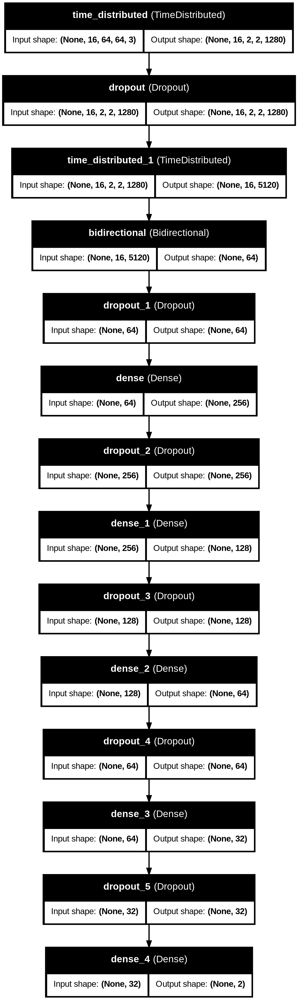

In [90]:
# Constructing the Model
MoBiLSTM_model = create_model()

# Plot the structure of the contructed LRCN model.
plot_model(MoBiLSTM_model, 
           to_file = 'MobBiLSTM_model_structure_plot.png', 
           show_shapes = True, 
           show_layer_names = True)

# **Specifying Callbacks and Fitting**

In [91]:
# Create Early Stopping Callback to monitor the accuracy
early_stopping_callback = EarlyStopping(
    monitor = 'val_accuracy', 
    patience = 10, 
    restore_best_weights = True)

# Create ReduceLROnPlateau Callback to reduce overfitting by decreasing learning
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.6,
    patience=5,
    min_lr=0.00005,
    verbose=1)

# Compiling the model
MoBiLSTM_model.compile(
    loss = 'categorical_crossentropy', 
    optimizer = 'sgd', 
    metrics = ["accuracy"])

# Fitting the model
MobBiLSTM_model_history = MoBiLSTM_model.fit(
    x = features_train, 
    y = labels_train, 
    epochs = 20, 
    batch_size = 8 ,
    shuffle = True, 
    validation_split = 0.2, 
    callbacks = [early_stopping_callback,reduce_lr])

Epoch 1/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 144s 303ms/step - accuracy: 0.5142 - loss: 0.6998 - val_accuracy: 0.5417 - val_loss: 0.6886 - learning_rate: 0.0100
Epoch 2/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 34s 191ms/step - accuracy: 0.5573 - loss: 0.6816 - val_accuracy: 0.5889 - val_loss: 0.6710 - learning_rate: 0.0100
Epoch 3/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 34s 191ms/step - accuracy: 0.6546 - loss: 0.6289 - val_accuracy: 0.7806 - val_loss: 0.5336 - learning_rate: 0.0100
Epoch 4/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 34s 190ms/step - accuracy: 0.7721 - loss: 0.5081 - val_accuracy: 0.6500 - val_loss: 0.8253 - learning_rate: 0.0100
Epoch 5/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 35s 193ms/step - accuracy: 0.8242 - loss: 0.4431 - val_accuracy: 0.8639 - val_loss: 0.3621 - learning_rate: 0.0100
Epoch 6/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 35s 193ms/step - accuracy: 0.8443 - loss: 0.3849 - val_accuracy: 0.7917 - val_loss: 0.4605 - learning_rate: 0.0100
Epoch 7/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 35s 193ms/step - accuracy: 0.

In [92]:
model_evaluation_history = MoBiLSTM_model.evaluate(features_test, labels_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 21s 115ms/step - accuracy: 0.9300 - loss: 0.2099


# **Model Evaluation**

In [100]:
def plot_metric(model_training_history, metric_name_1, metric_name_2, plot_name):
    
    metric_value_1 = model_training_history.history[metric_name_1]
    metric_value_2 = model_training_history.history[metric_name_2]
    
    # Get the Epochs Count
    epochs = range(len(metric_value_1))

    plt.figure(figsize=(7, 5))
    plt.plot(epochs, metric_value_1, 'blue', label = metric_name_1)
    plt.plot(epochs, metric_value_2, 'orange', label = metric_name_2)
 
    plt.title(str(plot_name))
 
    plt.legend()

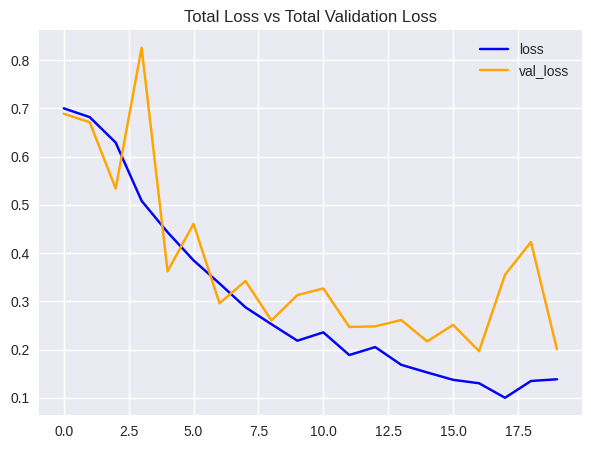

In [101]:
plot_metric(MobBiLSTM_model_history, 'loss', 'val_loss', 'Total Loss vs Total Validation Loss')

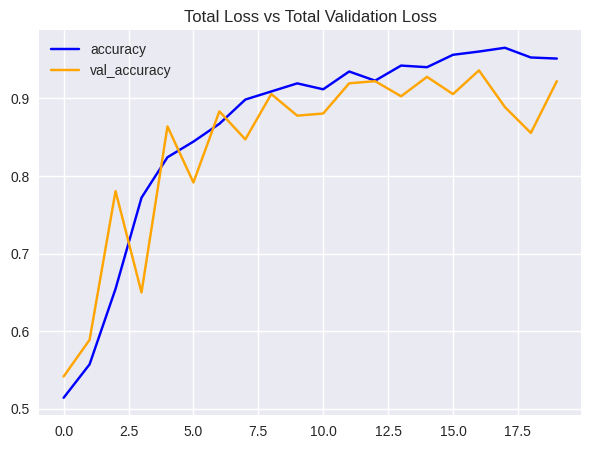

In [102]:
plot_metric(MobBiLSTM_model_history, 'accuracy', 'val_accuracy', 'Total Loss vs Total Validation Loss')

# **Predicting the Test Set**

In [103]:
labels_predict = MoBiLSTM_model.predict(features_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 34s 3s/step 


In [107]:
labels_test_normal.shape , labels_predict.shape

((200,), (200,))

# **Accuracy Score**

In [108]:
from sklearn.metrics import accuracy_score
AccScore = accuracy_score(labels_predict, labels_test_normal)
print('Accuracy Score is : ', AccScore)

Accuracy Score is :  0.93


# **Confusion Matrix**

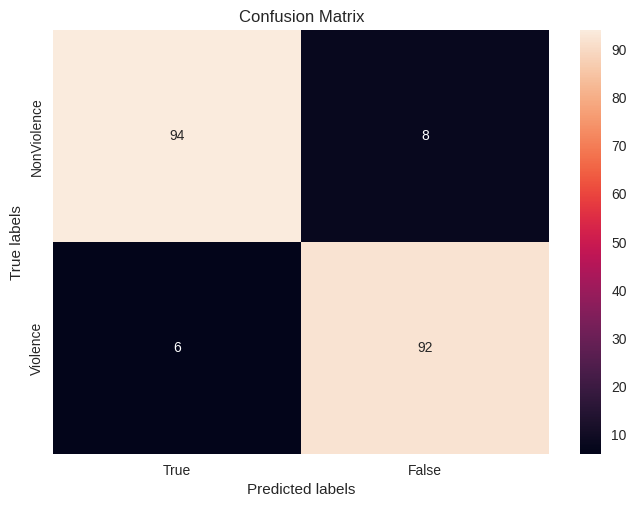

In [109]:
import seaborn as sns 
from sklearn.metrics import confusion_matrix

ax= plt.subplot()
cm=confusion_matrix(labels_test_normal, labels_predict)
sns.heatmap(cm, annot=True, fmt='g', ax=ax);  

ax.set_xlabel('Predicted labels');ax.set_ylabel('True labels'); 
ax.set_title('Confusion Matrix'); 
ax.xaxis.set_ticklabels(['True', 'False']); ax.yaxis.set_ticklabels(['NonViolence', 'Violence']);

In [110]:
from sklearn.metrics import classification_report

ClassificationReport = classification_report(labels_test_normal,labels_predict)
print('Classification Report is : \n', ClassificationReport)

Classification Report is : 
               precision    recall  f1-score   support

           0       0.94      0.92      0.93       102
           1       0.92      0.94      0.93        98

    accuracy                           0.93       200
   macro avg       0.93      0.93      0.93       200
weighted avg       0.93      0.93      0.93       200



In [112]:
def predict_frames(video_file_path, output_file_path, SEQUENCE_LENGTH):
    
    # Read from the video file.
    video_reader = cv2.VideoCapture(video_file_path)
 
    # Get the width and height of the video.
    original_video_width = int(video_reader.get(cv2.CAP_PROP_FRAME_WIDTH))
    original_video_height = int(video_reader.get(cv2.CAP_PROP_FRAME_HEIGHT))
 
    # VideoWriter to store the output video in the disk.
    video_writer = cv2.VideoWriter(output_file_path, cv2.VideoWriter_fourcc('m', 'p', '4', 'v'), 
                                    video_reader.get(cv2.CAP_PROP_FPS), (original_video_width, original_video_height))
 
    # Declare a queue to store video frames.
    frames_queue = deque(maxlen = SEQUENCE_LENGTH)
 
    # Store the predicted class in the video.
    predicted_class_name = ''
 
    # Iterate until the video is accessed successfully.
    while video_reader.isOpened():
 
        ok, frame = video_reader.read() 
        
        if not ok:
            break
 
        # Resize the Frame to fixed Dimensions.
        resized_frame = cv2.resize(frame, (IMAGE_HEIGHT, IMAGE_WIDTH))
        
        # Normalize the resized frame 
        normalized_frame = resized_frame / 255
 
        # Appending the pre-processed frame into the frames list.
        frames_queue.append(normalized_frame)
 
        # We Need at Least number of SEQUENCE_LENGTH Frames to perform a prediction.
        # Check if the number of frames in the queue are equal to the fixed sequence length.
        if len(frames_queue) == SEQUENCE_LENGTH:                        
 
            # Pass the normalized frames to the model and get the predicted probabilities.
            predicted_labels_probabilities = MoBiLSTM_model.predict(np.expand_dims(frames_queue, axis = 0))[0]
 
            # Get the index of class with highest probability.
            predicted_label = np.argmax(predicted_labels_probabilities)
 
            # Get the class name using the retrieved index.
            predicted_class_name = CLASSES_LIST[predicted_label]
 
        # Write predicted class name on top of the frame.
        if predicted_class_name == "Violence":
            cv2.putText(frame, predicted_class_name, (5, 100), cv2.FONT_HERSHEY_SIMPLEX, 3, (0, 0, 255), 12)
        else:
            cv2.putText(frame, predicted_class_name, (5, 100), cv2.FONT_HERSHEY_SIMPLEX, 3, (0, 255, 0), 12)
         
        # Write The frame into the disk using the VideoWriter
        video_writer.write(frame)                       
        
    video_reader.release()
    video_writer.release()


In [130]:
plt.style.use("default")

# To show Random Frames from the saved output predicted video (output predicted video doesn't show on the notebook but can be downloaded)
def show_pred_frames(pred_video_path): 

    plt.figure(figsize=(20,15))

    video_reader = cv2.VideoCapture(pred_video_path)

    # Get the number of frames in the video.
    frames_count = int(video_reader.get(cv2.CAP_PROP_FRAME_COUNT))
    
    # Get Random Frames from the video then Sort it
    random_range = sorted(random.sample(range (SEQUENCE_LENGTH , frames_count ), 12))
        
    for counter, random_index in enumerate(random_range, 1):
        
        plt.subplot(5, 4, counter)

        # Set the current frame position of the video.  
        video_reader.set(cv2.CAP_PROP_POS_FRAMES, random_index)
          
        ok, frame = video_reader.read() 

        if not ok:
          break 

        frame = cv2.cvtColor(frame , cv2.COLOR_BGR2RGB)

        plt.imshow(frame);ax.figure.set_size_inches(20,20);plt.tight_layout()
                            
    video_reader.release()


In [131]:
# Construct the output video path.
test_videos_directory = 'test_videos'
os.makedirs(test_videos_directory, exist_ok = True)
 
output_video_file_path = f'{test_videos_directory}/Output-Test-Video.mp4'

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

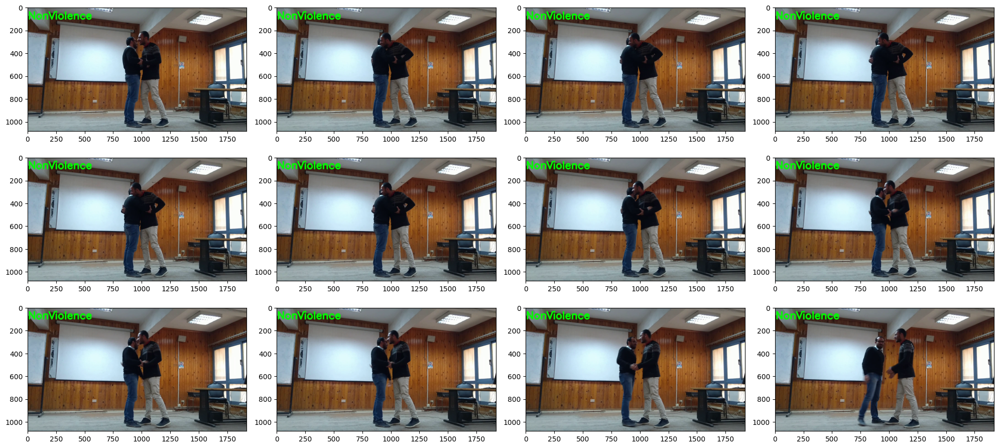

In [133]:
# Specifying video to be predicted
input_video_file_path = "/kaggle/input/datasets/mohamedmustafa/real-life-violence-situations-dataset/Real Life Violence Dataset/NonViolence/NV_1.mp4"

# Perform Prediction on the Test Video.
predict_frames(input_video_file_path, output_video_file_path, SEQUENCE_LENGTH)

# Show random frames from the output video
show_pred_frames(output_video_file_path)

In [134]:
# Play the actual video
Play_Video(input_video_file_path)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

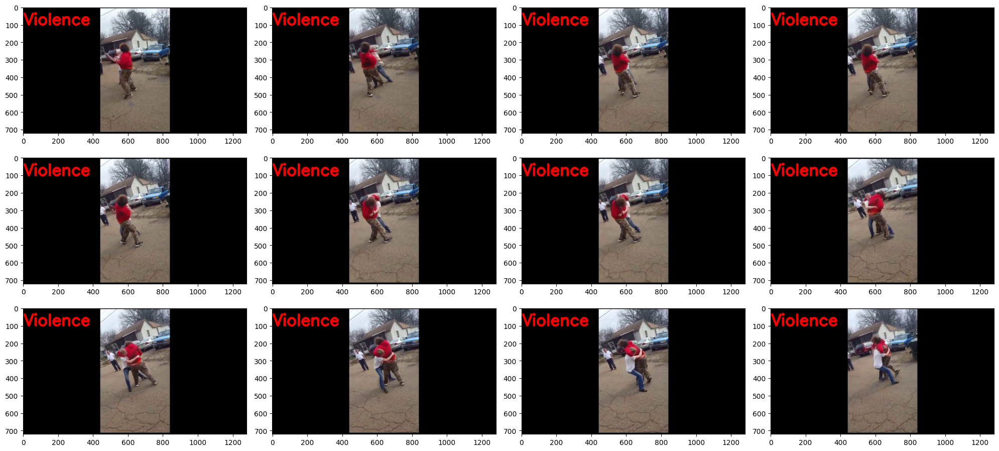

In [141]:
# Specifying video to be predicted
input_video_file_path = "/kaggle/input/datasets/mohamedmustafa/real-life-violence-situations-dataset/Real Life Violence Dataset/Violence/V_120.mp4"

# Perform Prediction on the Test Video.
predict_frames(input_video_file_path, output_video_file_path, SEQUENCE_LENGTH)

# Show random frames from the output video
show_pred_frames(output_video_file_path)

In [142]:
# Play the actual video
Play_Video(input_video_file_path)

In [143]:
MoBiLSTM_model.save("Real_Life_Violence_Detation_MoBiLSTM_model.h5")